# Subroutine 4

### Installing necessary packages

In [16]:
! pip install numpy
! pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


### Defining Function for matrix-matrix multiplication 

In [17]:
def packed_lu_product(LU, n):
    """
    Compute M = L U, where unit lower triangular L and upper triangular U
    are packed together in one n x n array LU.
    The unit diagonal of L and the zeros are never stored or multiplied.

    m_ij = sum_{k < min(i,j)} l_ik u_kj  +  (u_ij if i <= j else l_ij u_jj)
    """
    M = [[0.0] * n for _ in range(n)]

    for i in range(n):
        for j in range(n):
            s = 0.0
            for k in range(min(i, j)):
                s = s + LU[i][k] * LU[k][j]

            if i <= j:
                s = s + LU[i][j]                 # l_ii = 1, no multiplication
            else:
                s = s + LU[i][j] * LU[j][j]      # l_ij * u_jj

            M[i][j] = s

    return M

### Testing using the known result 

In [18]:
import numpy as np

# Packed 3x3 array: strictly lower part = L (below the unit diagonal),
# diagonal and upper part = U
LU = [[2, 1, 3],
      [1, 4, 2],
      [3, 2, 5]]

# Hand-worked factors, for reference:
# L = [[1, 0, 0],      U = [[2, 1, 3],
#      [1, 1, 0],           [0, 4, 2],
#      [3, 2, 1]]           [0, 0, 5]]

M = packed_lu_product(LU, 3)
print("calculated M using subroutine=")
for row in M:
    print(row)

M_expected = [[2,  1,  3],
              [2,  5,  5],
              [6, 11, 18]]   # L @ U, worked out by hand

if M == M_expected:
    print("yeeee, it works!")
else:
    print("oh no, it failed:", M, "!=", M_expected)

# Cross-check with NumPy by unpacking L and U explicitly
LU_np = np.array(LU, dtype=float)
L = np.tril(LU_np, -1) + np.eye(3)
U = np.triu(LU_np)
M_true = L @ U

print("\nL =\n", L)
print("U =\n", U)
print("Calculated M using numpy =\n", M_true)

abs_err = np.linalg.norm(np.array(M) - M_true)
rel_err = abs_err / np.linalg.norm(M_true)
print("absolute error =", abs_err)
print("relative error =", rel_err)

calculated M using subroutine=
[2.0, 1.0, 3.0]
[2.0, 5.0, 5.0]
[6.0, 11.0, 18.0]
yeeee, it works!

L =
 [[1. 0. 0.]
 [1. 1. 0.]
 [3. 2. 1.]]
U =
 [[2. 1. 3.]
 [0. 4. 2.]
 [0. 0. 5.]]
Calculated M using numpy =
 [[ 2.  1.  3.]
 [ 2.  5.  5.]
 [ 6. 11. 18.]]
absolute error = 0.0
relative error = 0.0


In [19]:
import numpy as np

n = int(input("Enter n: "))
rng = np.random.default_rng(seed=42)  # for reproducibility

# 1. Random packed array LU (n^2 free entries), then unpack L and U for the reference
LU = rng.standard_normal((n, n))
L = np.tril(LU, -1) + np.eye(n)   # unit lower triangular
U = np.triu(LU)                   # upper triangular
#print("LU (packed) =\n", LU)
#print("L =\n", L)
#print("U =\n", U)

# 2. Our routine vs NumPy
M_comp = np.array(packed_lu_product(LU.tolist(), n))
M_true = L @ U

# 3. Errors in several matrix norms (1, inf, Frobenius, and 2 via the library routine)
D = M_comp - M_true
norms = {"1": 1, "inf": np.inf, "Frobenius": "fro", "2": 2}

#print("\nM computed =\n", M_comp)
#print("M true =\n", M_true)
print(f"\n{'norm':>10s}{'abs error':>14s}{'rel error':>14s}")
for name, p in norms.items():
    abs_err = np.linalg.norm(D, p)
    nrm = np.linalg.norm(M_true, p)
    rel_err = abs_err / nrm if nrm > 0 else abs_err
    print(f"{name:>10s}{abs_err:14.3e}{rel_err:14.3e}")

#print("\nmachine epsilon =", np.finfo(float).eps)


      norm     abs error     rel error
         1     3.557e-12     5.122e-16
       inf     3.477e-12     5.048e-16
 Frobenius     3.400e-12     5.261e-16
         2     4.123e-13     4.731e-16


In [20]:
import numpy as np

n = int(input("Enter n: "))
rng = np.random.default_rng(seed=42)  # for reproducibility

# 1. Random packed array LU (n^2 free entries), then unpack L and U for the reference
LU = rng.standard_normal((n, n))
L = np.tril(LU, -1) + np.eye(n)   # unit lower triangular
U = np.triu(LU)                   # upper triangular
print("LU (packed) =\n", LU)
print("L =\n", L)
print("U =\n", U)

# 2. Our routine vs NumPy
M_comp = np.array(packed_lu_product(LU.tolist(), n))
M_true = L @ U

# 3. Errors in several matrix norms (1, inf, Frobenius, and 2 via the library routine)
D = M_comp - M_true
norms = {"1": 1, "inf": np.inf, "Frobenius": "fro", "2": 2}

print("\nM computed =\n", M_comp)
print("M true =\n", M_true)
print(f"\n{'norm':>10s}{'abs error':>14s}{'rel error':>14s}")
for name, p in norms.items():
    abs_err = np.linalg.norm(D, p)
    nrm = np.linalg.norm(M_true, p)
    rel_err = abs_err / nrm if nrm > 0 else abs_err
    print(f"{name:>10s}{abs_err:14.3e}{rel_err:14.3e}")

#print("\nmachine epsilon =", np.finfo(float).eps)

LU (packed) =
 [[ 0.30471708 -1.03998411  0.7504512  ... -0.33560737 -1.990812
  -1.49506083]
 [ 1.36386223  0.89518498 -0.71948023 ...  0.12117795  0.13076419
   0.82375313]
 [-0.05928265 -0.72928694 -0.41447307 ... -1.15008549  0.71197702
  -1.18147907]
 ...
 [ 1.52071308  0.34206929  0.47362806 ...  0.62283739 -2.13599329
   0.39065522]
 [-1.45779753 -1.34008411 -0.6776749  ...  0.05517653  0.48460663
   0.3154596 ]
 [ 1.51478904 -1.9522214   0.02997487 ... -1.02724394 -1.23263372
   0.61400737]]
L =
 [[ 1.          0.          0.         ...  0.          0.
   0.        ]
 [ 1.36386223  1.          0.         ...  0.          0.
   0.        ]
 [-0.05928265 -0.72928694  1.         ...  0.          0.
   0.        ]
 ...
 [ 1.52071308  0.34206929  0.47362806 ...  1.          0.
   0.        ]
 [-1.45779753 -1.34008411 -0.6776749  ...  0.05517653  1.
   0.        ]
 [ 1.51478904 -1.9522214   0.02997487 ... -1.02724394 -1.23263372
   1.        ]]
U =
 [[ 0.30471708 -1.03998411  0.7504

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# n_max is the n entered earlier (the pure-Python routine is O(n^3), so keep it moderate, e.g. 100)
step = 10
n_max = n
n_list = list(range(1, n_max + 1, step))
K = len(n_list)

rng = np.random.default_rng(1)   # reproducible
ntrials = 20

norm_types = {"1": 1, "inf": np.inf, "Frobenius": "fro", "2": 2}

def rel_err(D, M, p):
    """Relative error ||D|| / ||M|| in the p-matrix-norm (absolute error if ||M|| = 0)."""
    a = np.linalg.norm(D, p)
    b = np.linalg.norm(M, p)
    return a / b if b > 0 else a

# Storage: for each norm, mean and max over trials at each n, plus all raw samples
mean_err = {name: np.zeros(K) for name in norm_types}
max_err  = {name: np.zeros(K) for name in norm_types}
all_err  = {name: [] for name in norm_types}   # list (per n) of arrays of trial errors

for k, n_k in enumerate(n_list):

    errs = {name: np.zeros(ntrials) for name in norm_types}

    for t in range(ntrials):
        LU = rng.standard_normal((n_k, n_k))          # random packed array
        L = np.tril(LU, -1) + np.eye(n_k)
        U = np.triu(LU)

        M_true = L @ U
        M_comp = np.array(packed_lu_product(LU.tolist(), n_k))   # our routine
        D = M_comp - M_true

        for name, p in norm_types.items():
            errs[name][t] = rel_err(D, M_true, p)

    for name in norm_types:
        all_err[name].append(errs[name])
        mean_err[name][k] = errs[name].mean()
        max_err[name][k]  = errs[name].max()

# Pool all trials across every n
pooled = {name: np.concatenate(all_err[name]) for name in norm_types}

# Summary table
print(f"{'Summary statistics':28s}" + "".join(f"{name:>12s}" for name in norm_types))
print(f"{'Mean of mean rel errors':28s}" + "".join(f"{mean_err[nm].mean():12.3e}" for nm in norm_types))
print(f"{'Max of max rel errors':28s}" + "".join(f"{max_err[nm].max():12.3e}" for nm in norm_types))
print(f"{'All-tests rel error mean':28s}" + "".join(f"{pooled[nm].mean():12.3e}" for nm in norm_types))
print(f"{'All-tests rel error var':28s}" + "".join(f"{pooled[nm].var(ddof=1):12.3e}" for nm in norm_types))


Summary statistics                     1         inf   Frobenius           2
Mean of mean rel errors        3.090e-16   3.284e-16   3.180e-16   2.898e-16
Max of max rel errors          5.322e-16   5.481e-16   5.267e-16   4.748e-16
All-tests rel error mean       3.090e-16   3.284e-16   3.180e-16   2.898e-16
All-tests rel error var        1.680e-32   1.713e-32   1.639e-32   1.321e-32


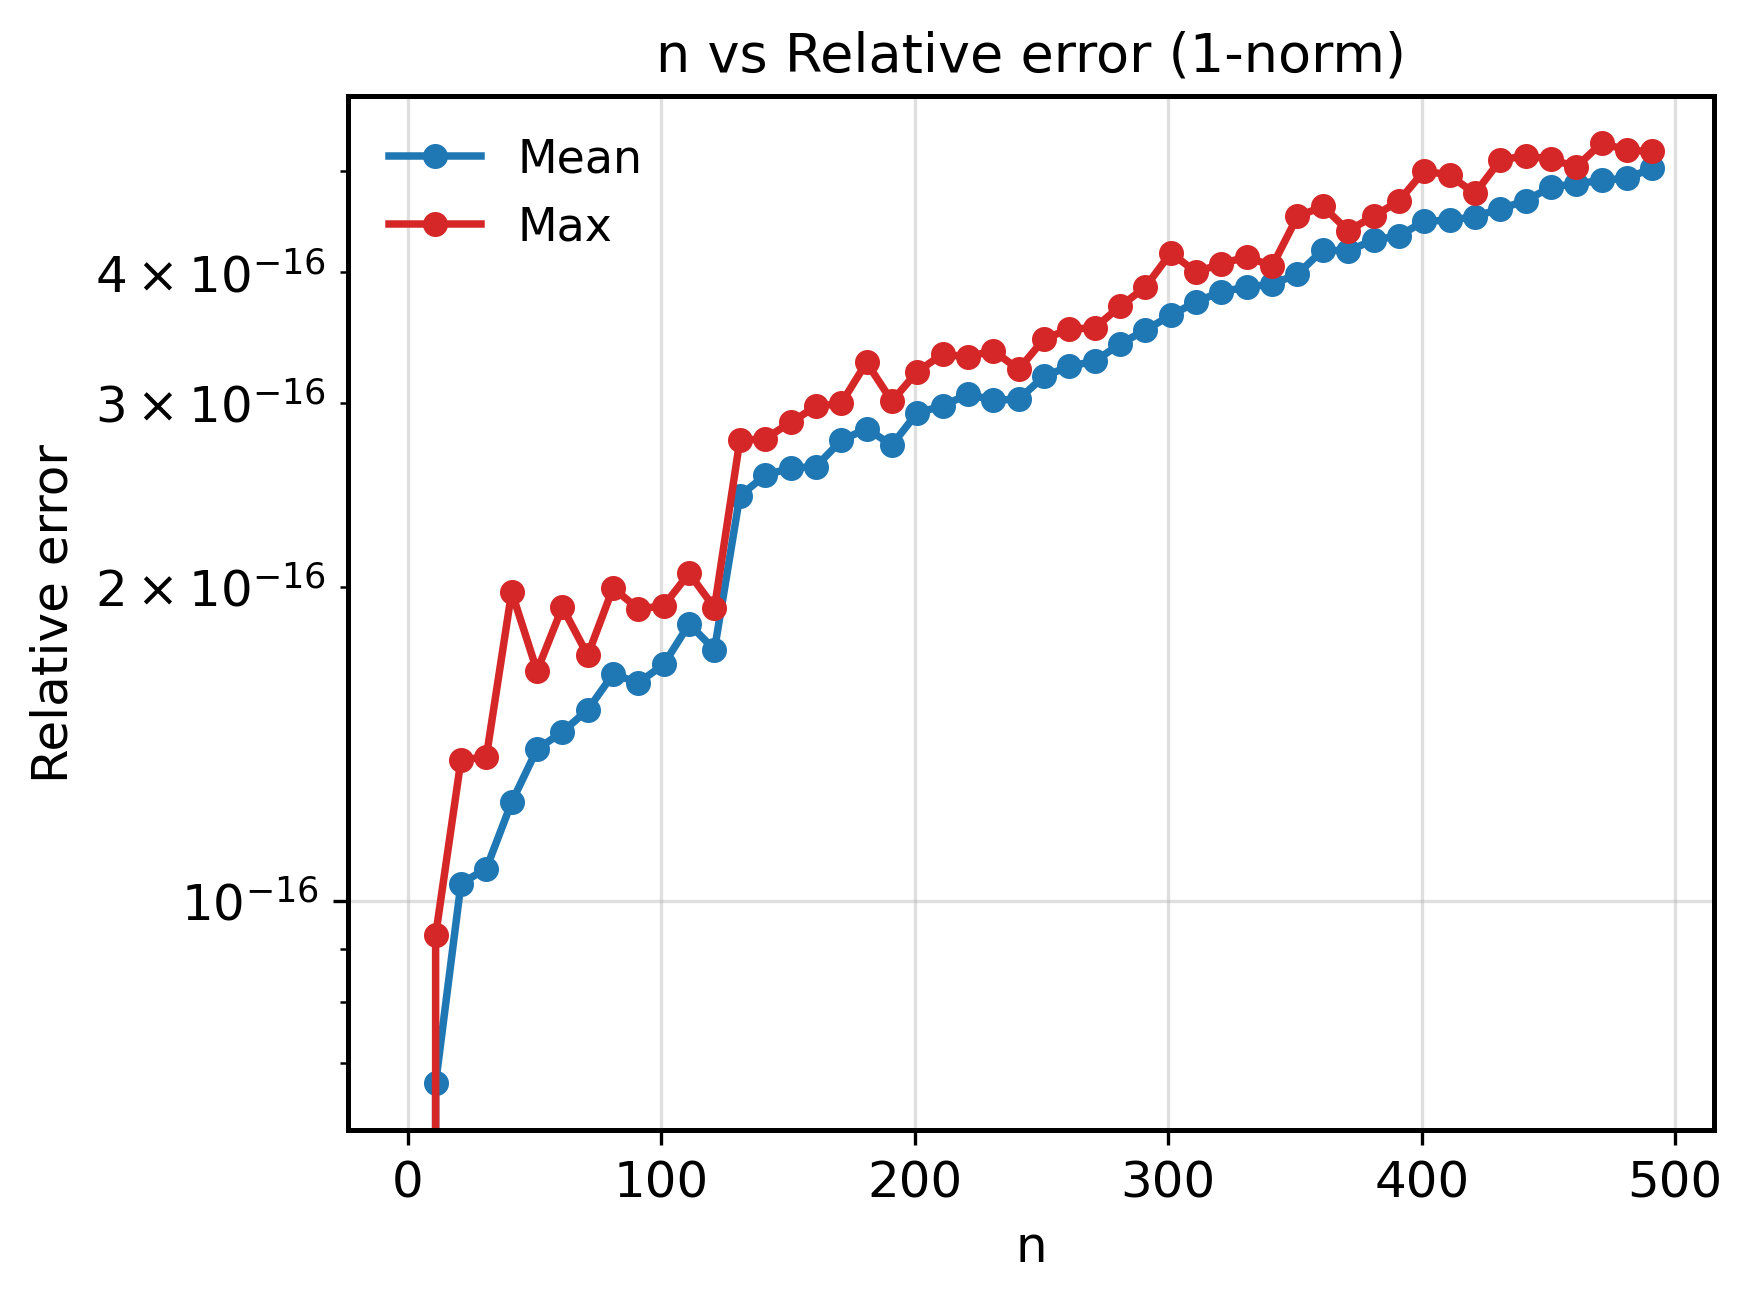

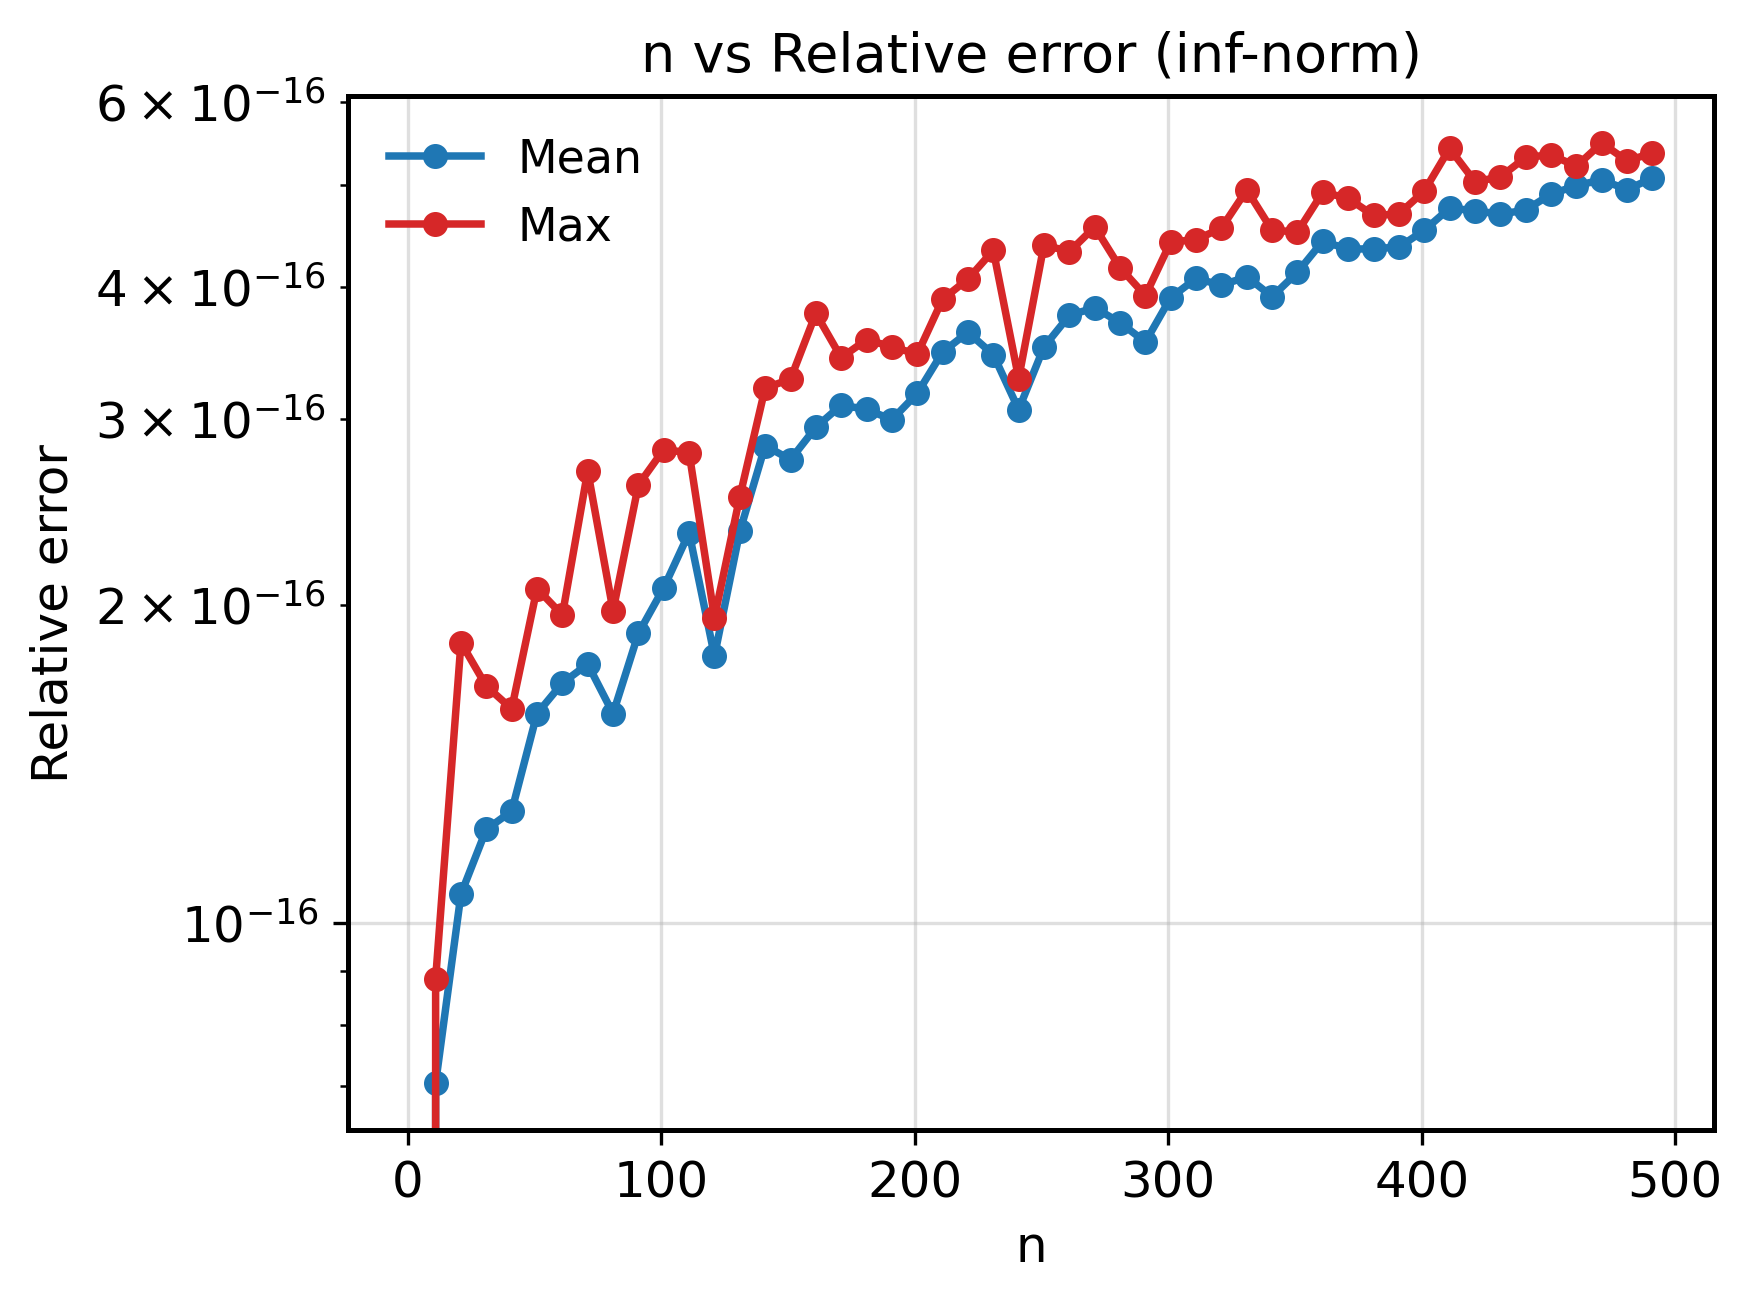

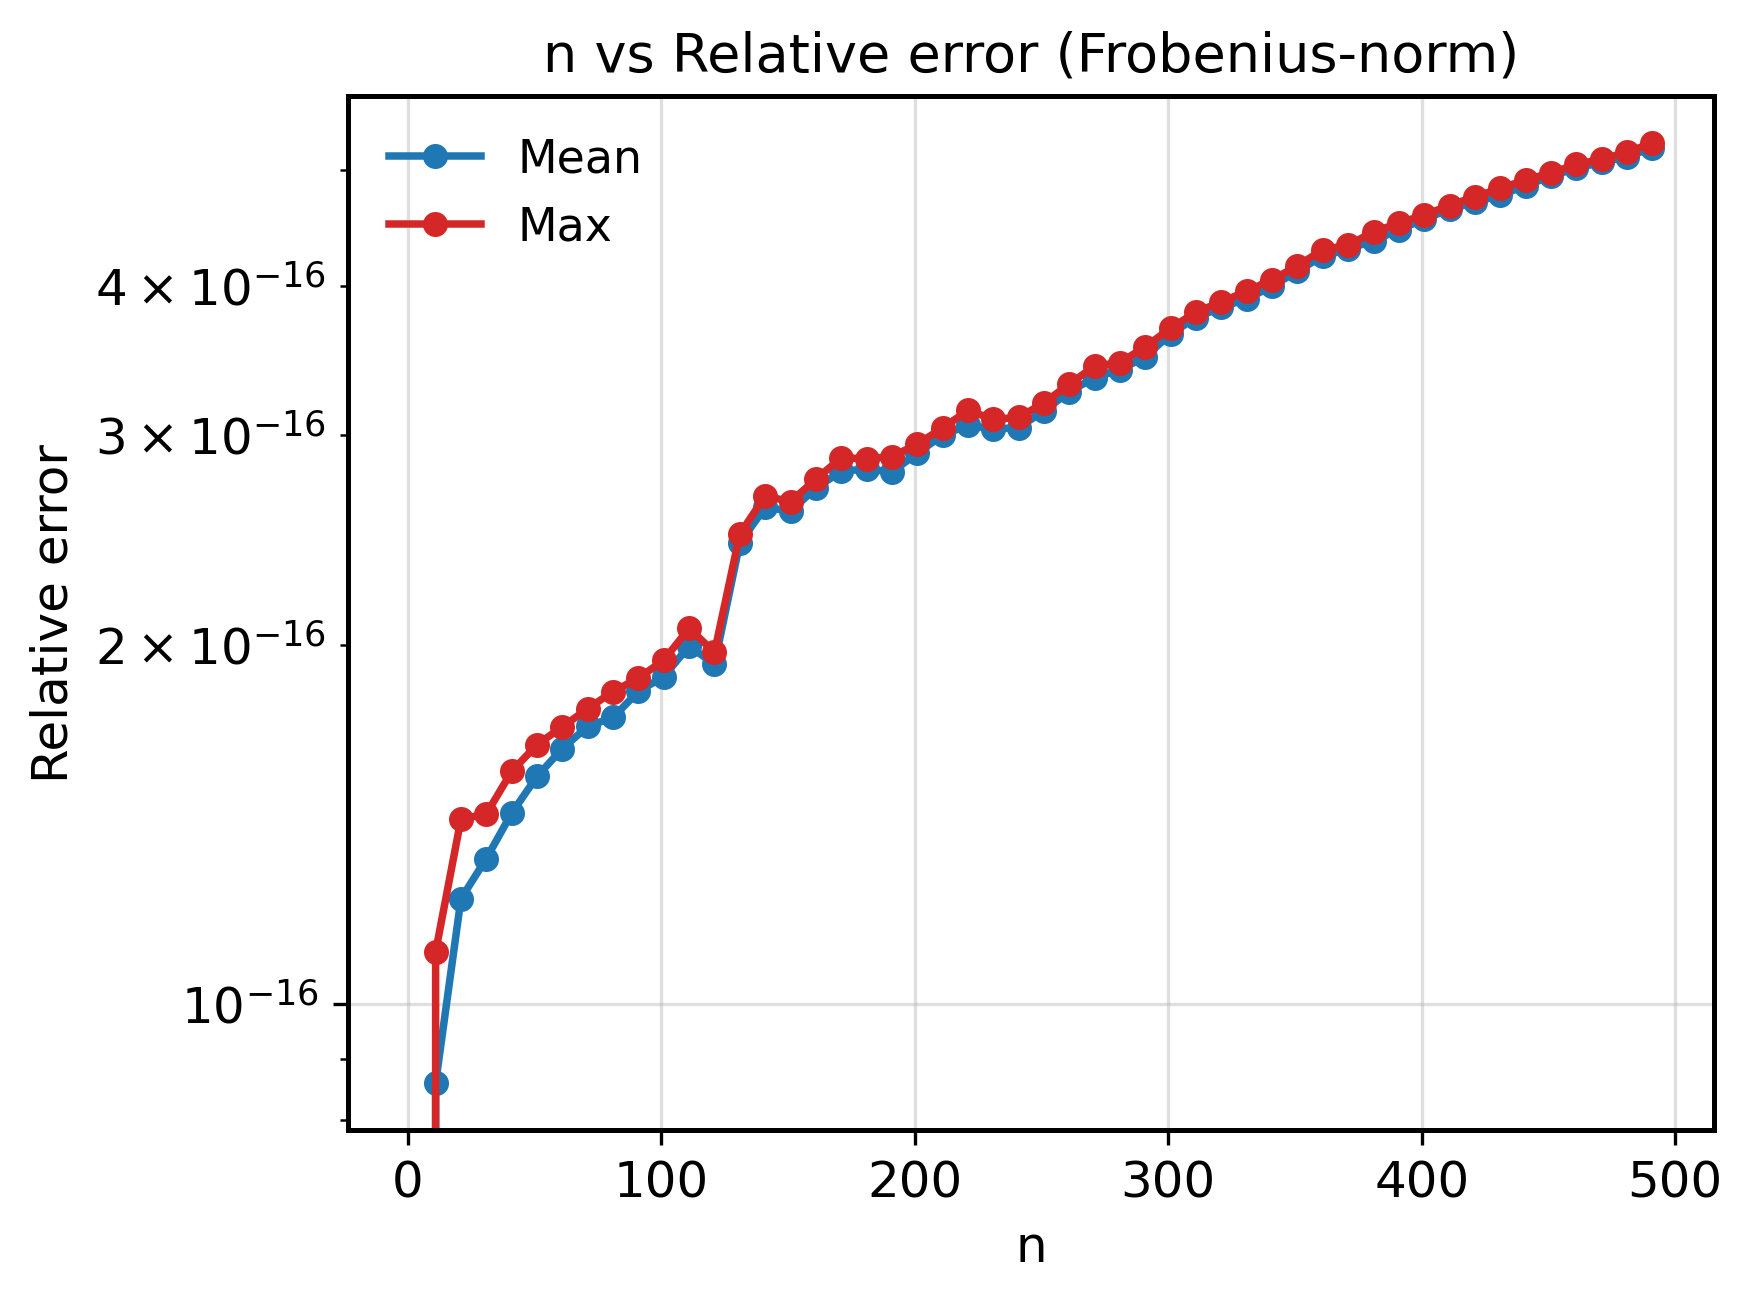

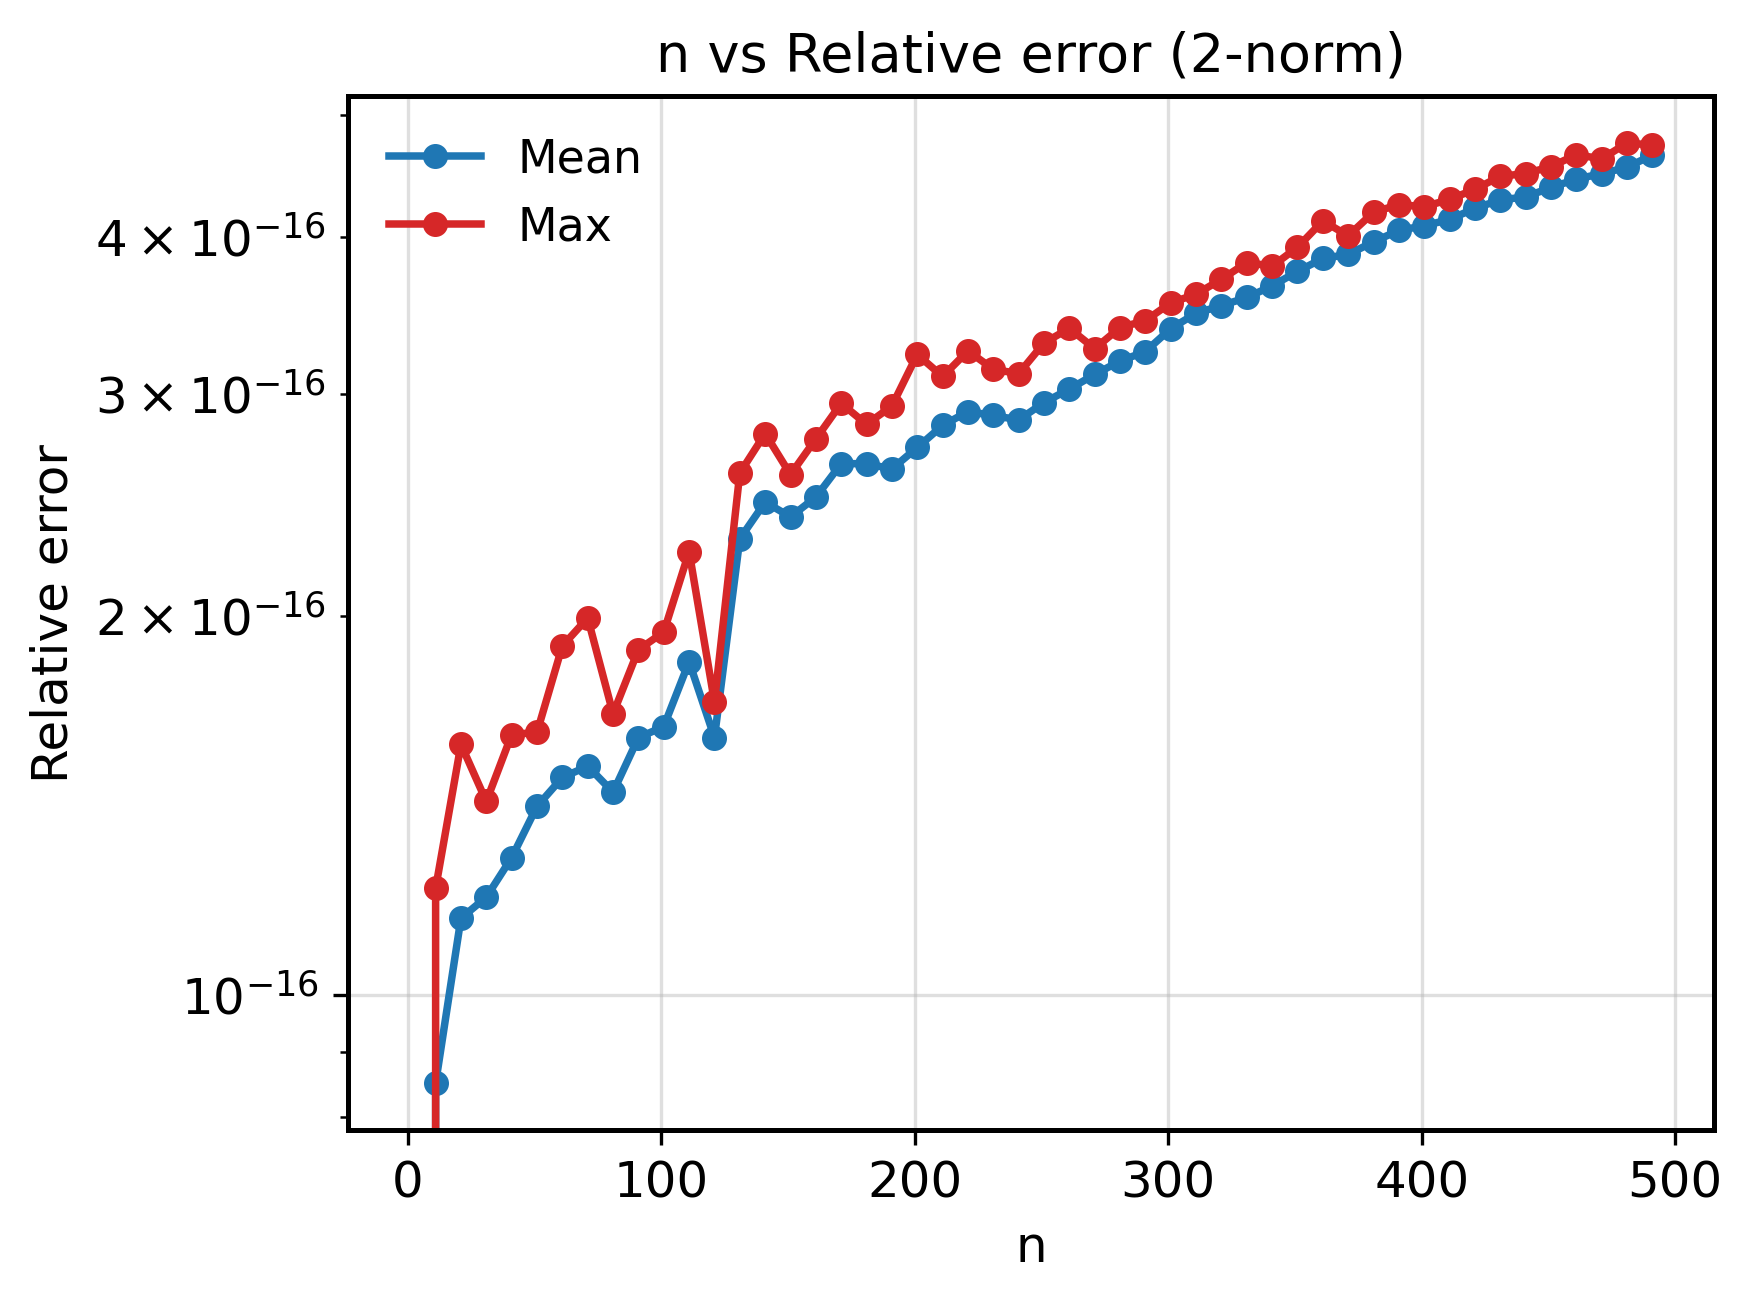

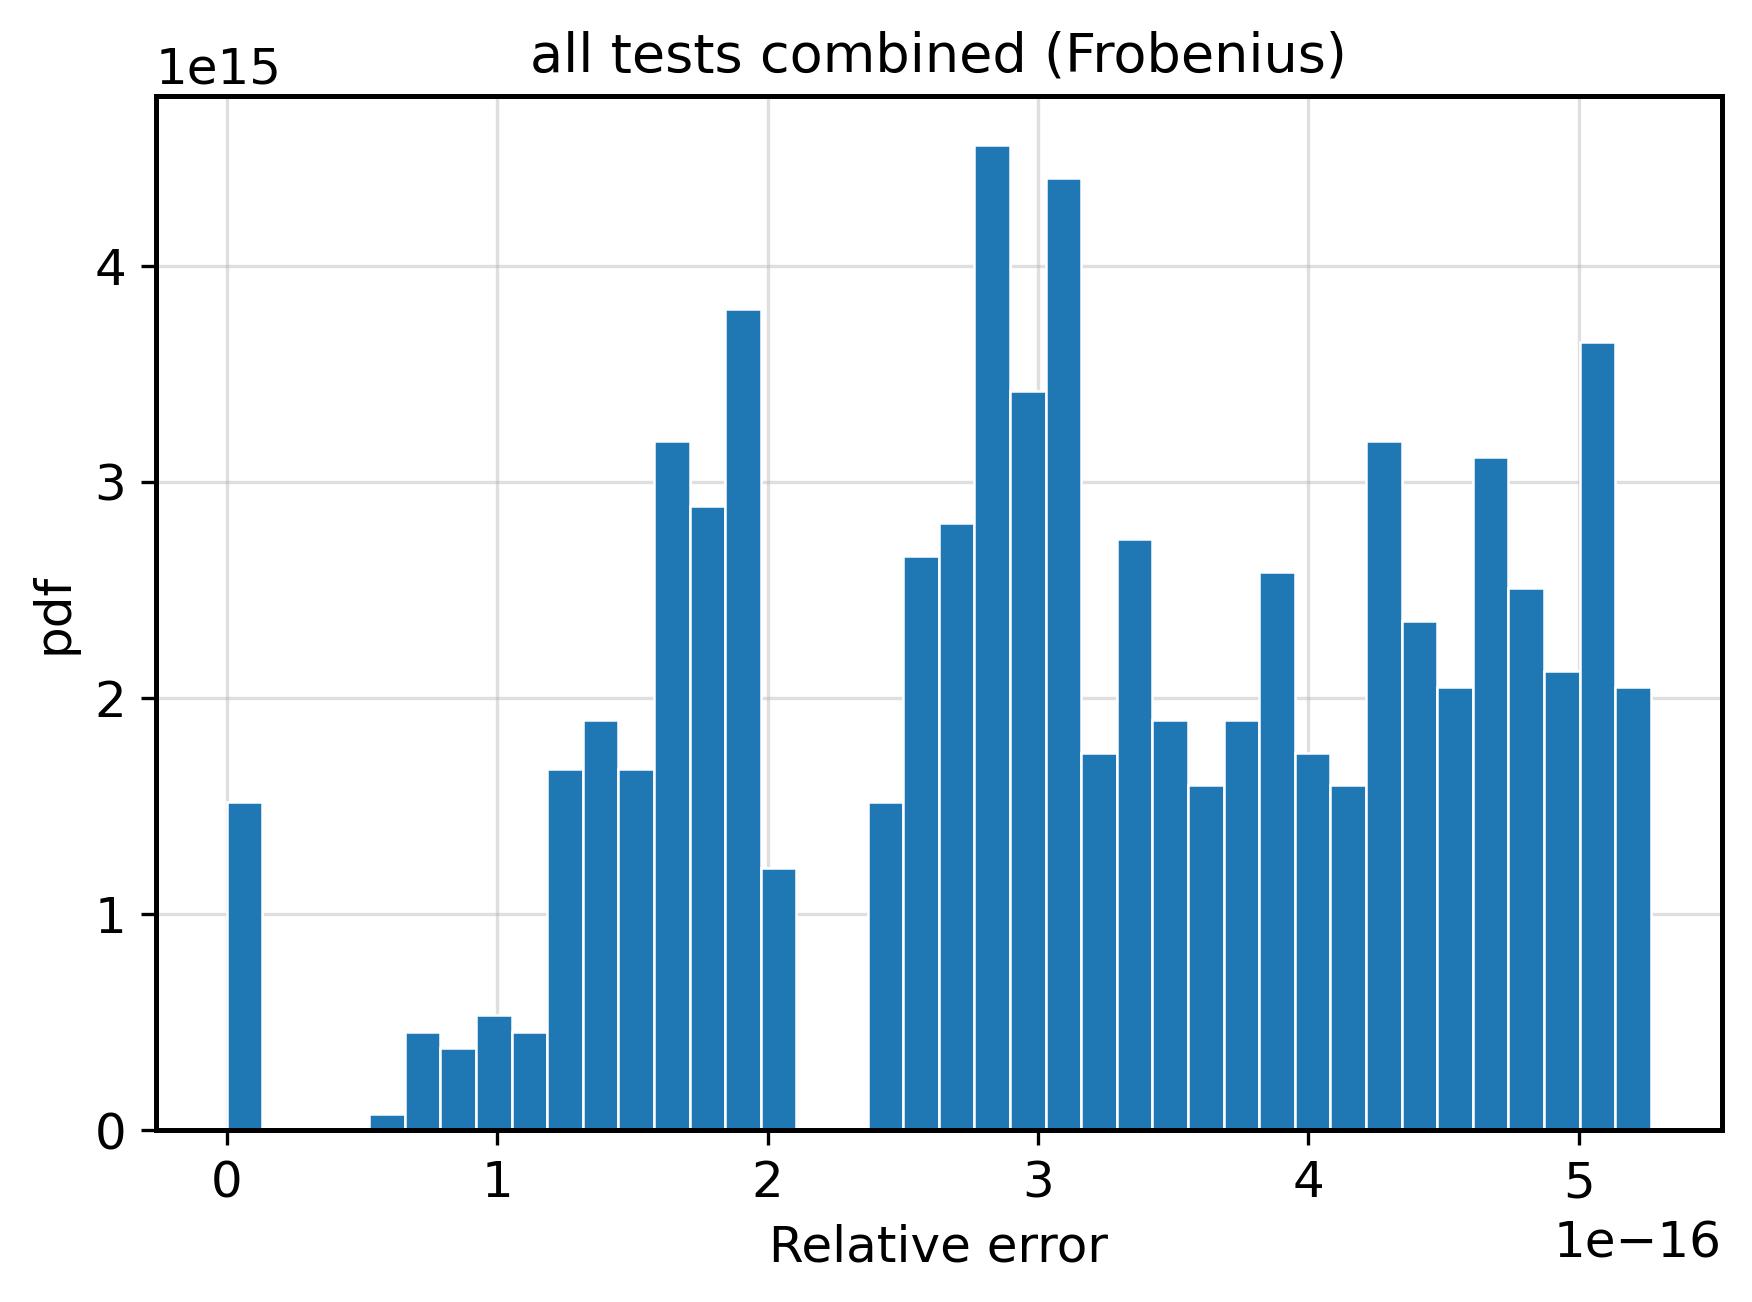

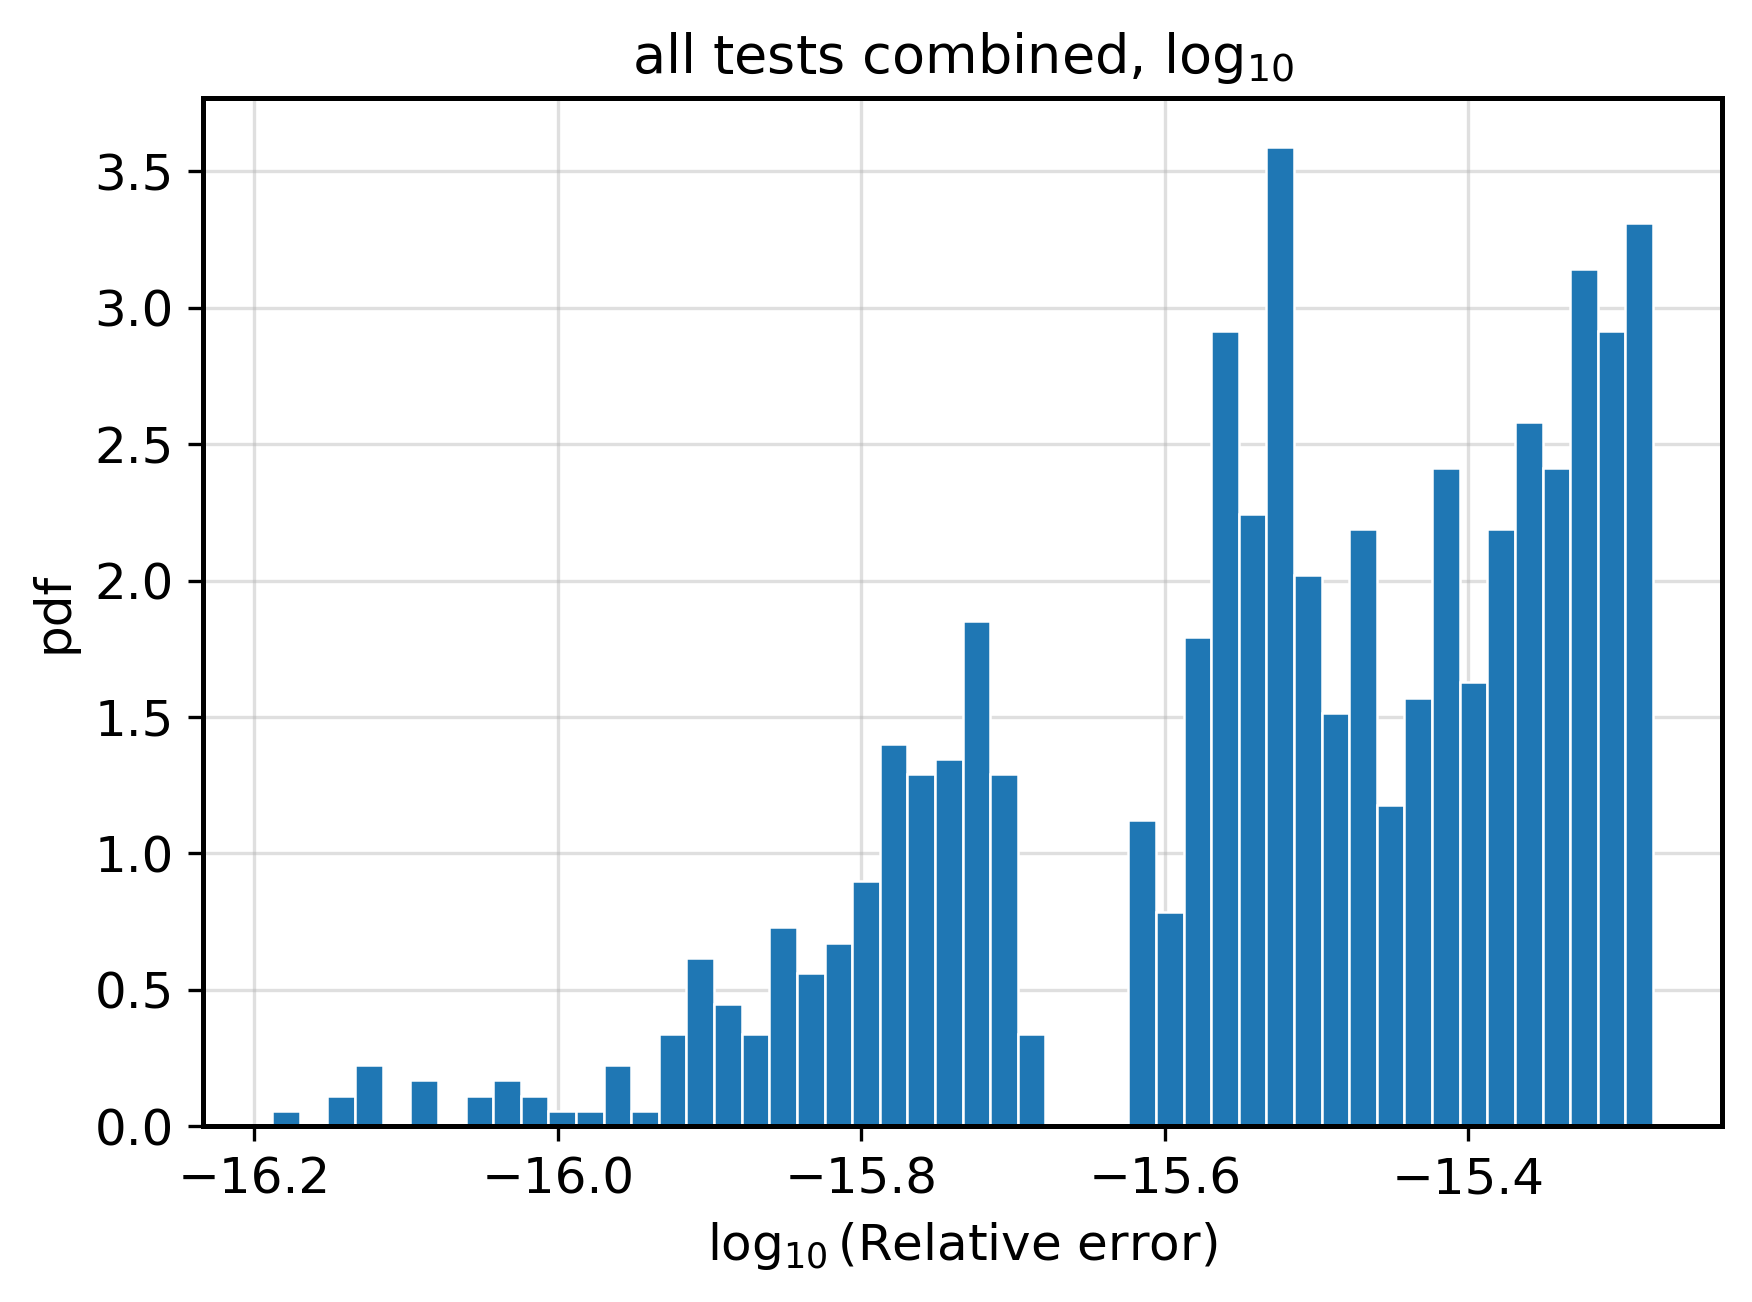

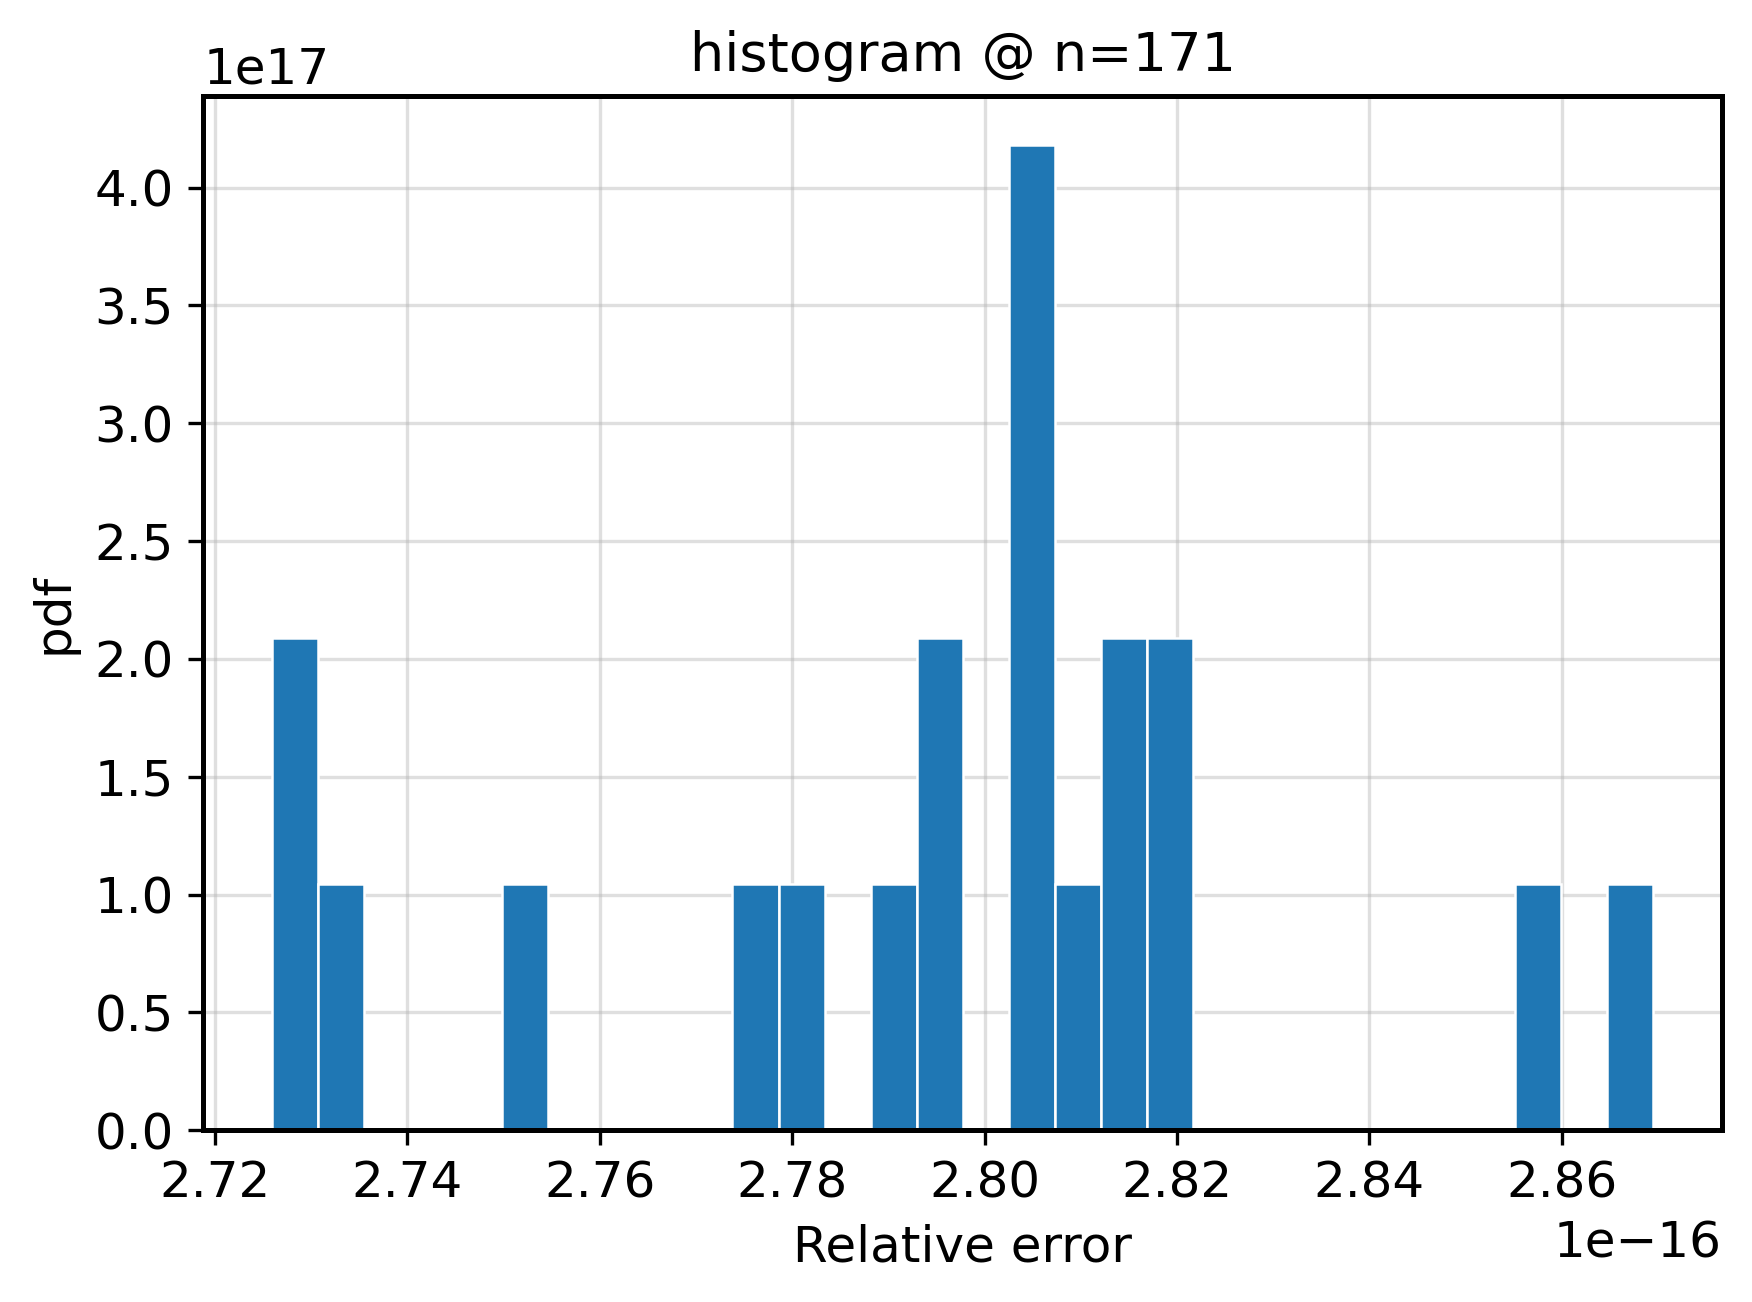

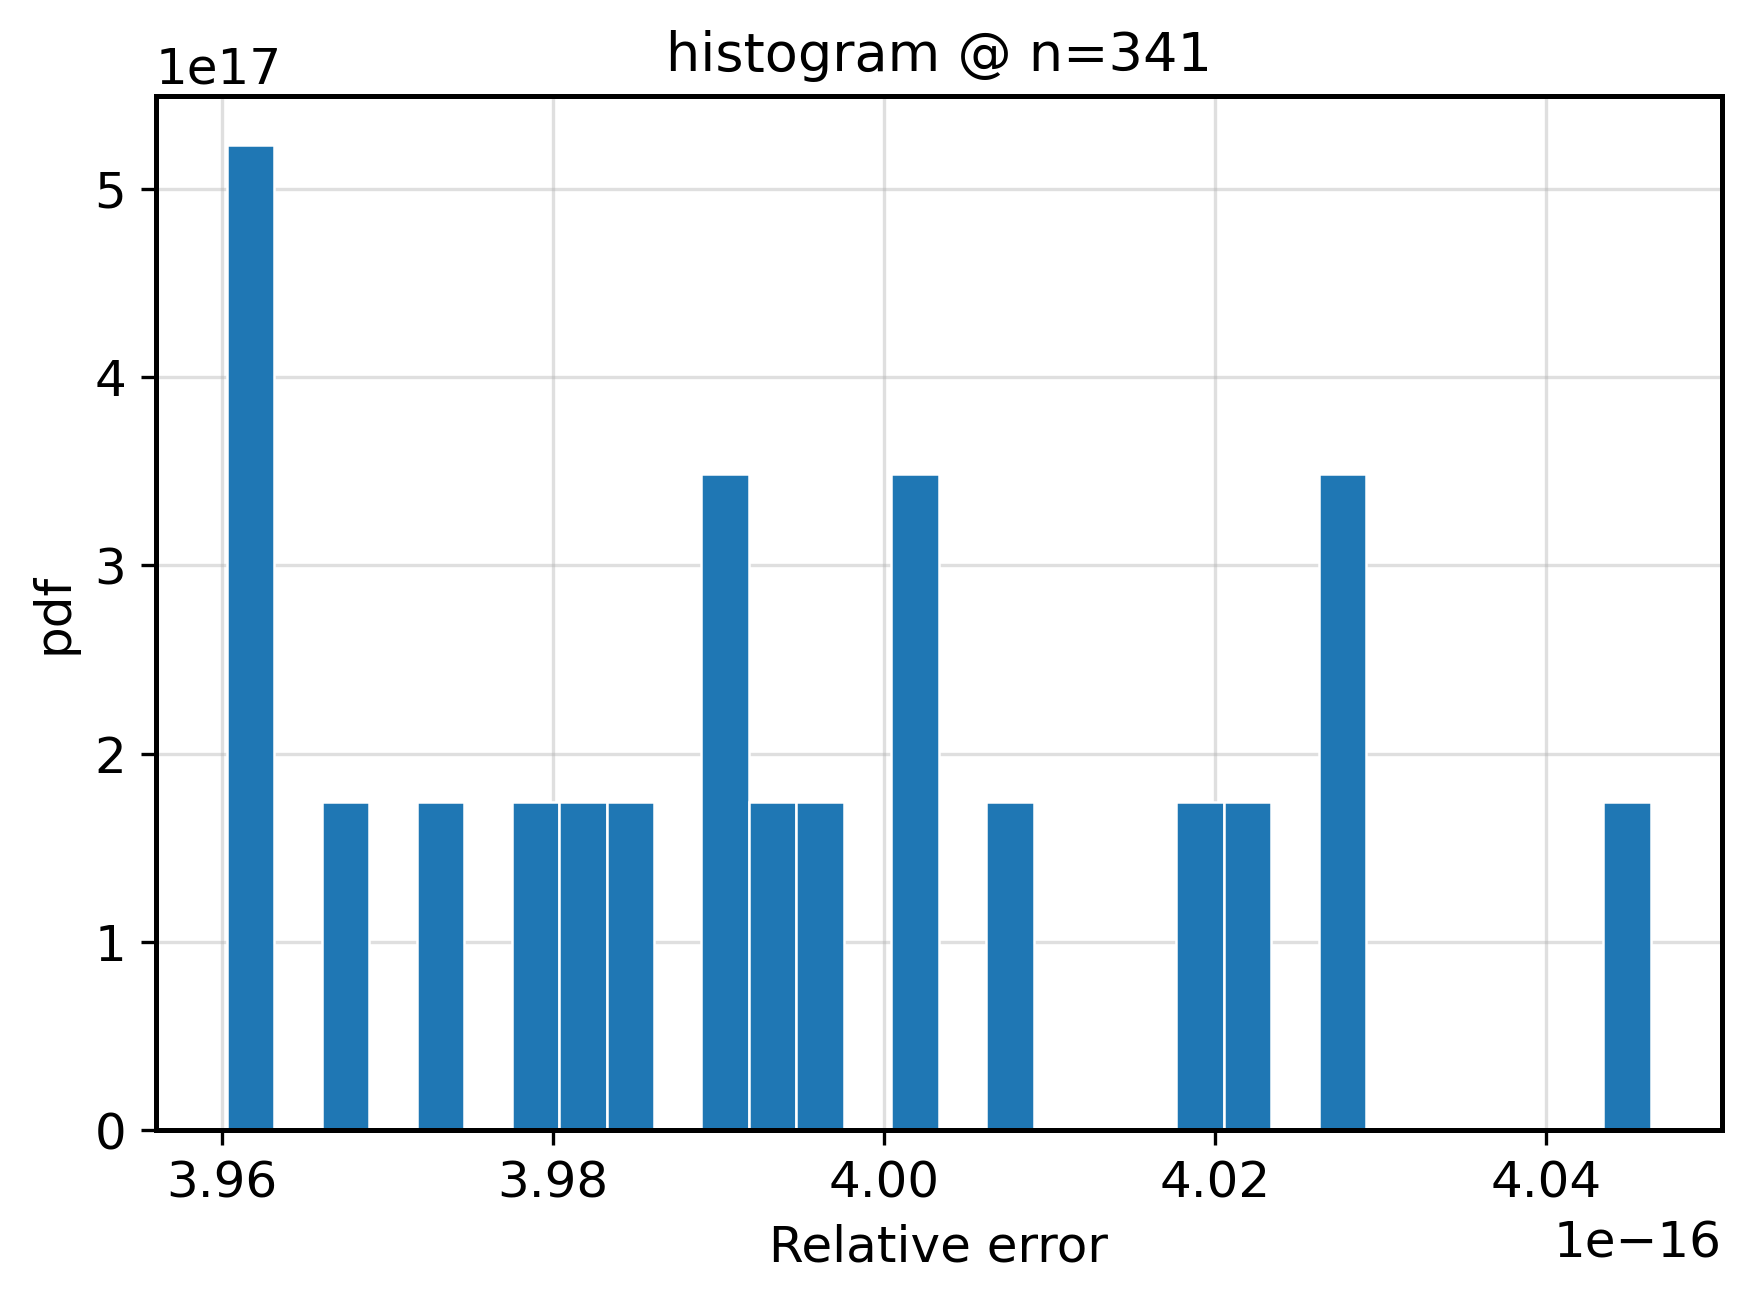

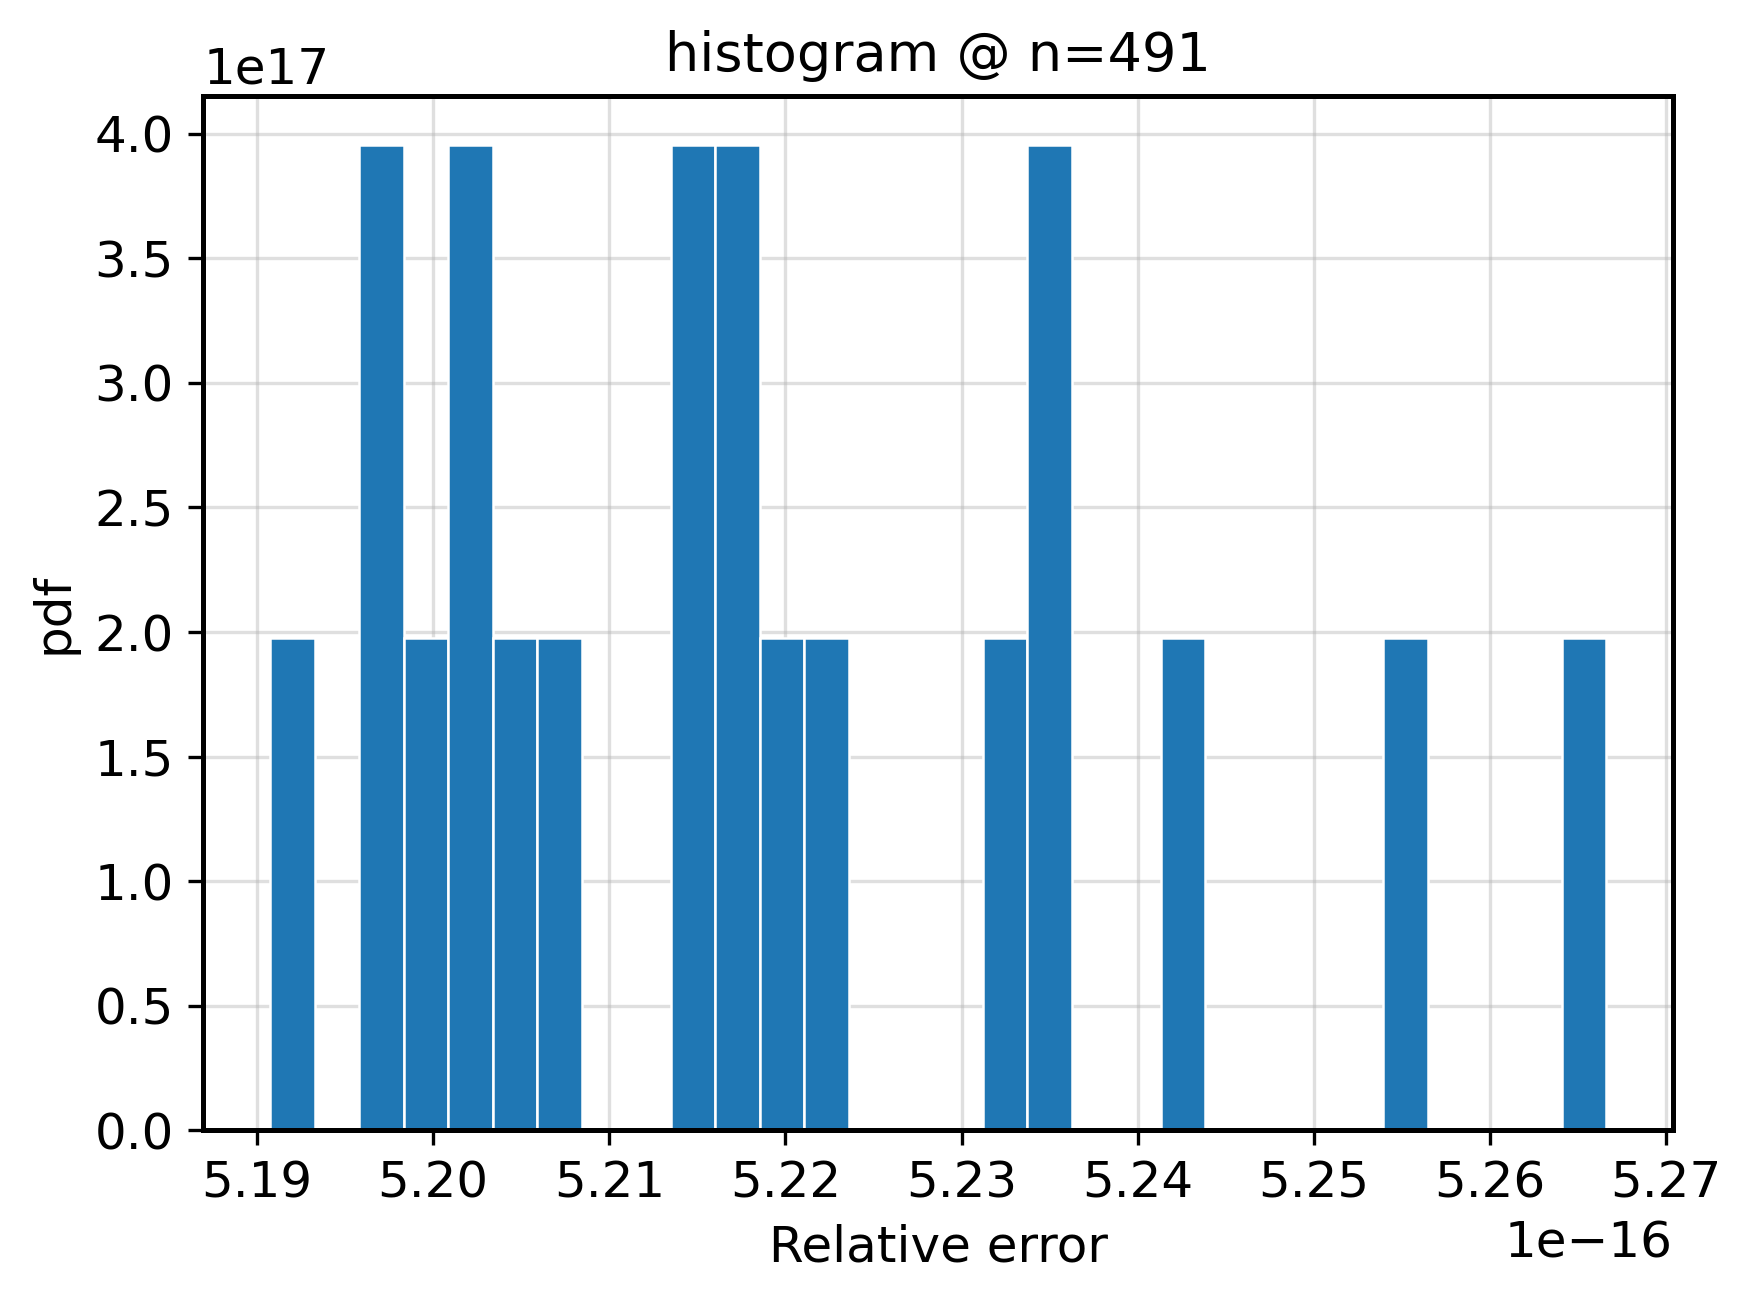

In [22]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "axes.spines.top": True,      # full border on all four sides
    "axes.spines.right": True,
    "axes.linewidth": 1.2,        # slightly thicker border
})

def save_fig(fname):
    plt.tight_layout()
    plt.savefig(f"{fname}.pdf", bbox_inches="tight")             # vector PDF
    plt.savefig(f"{fname}.png", dpi=300, bbox_inches="tight")
    plt.show()

def save_hist(data, xlabel, title, fname, bins):
    """One histogram per figure, same style as the line plots."""
    fig, a = plt.subplots(figsize=(6, 4.5))
    a.hist(data, bins=bins, density=True,
           color="#1f77b4", edgecolor="white", linewidth=0.6)
    a.set_xlabel(xlabel)
    a.set_ylabel("pdf")
    a.set_title(title)
    a.grid(True, which="major", alpha=0.4)
    a.set_axisbelow(True)                     # grid behind the bars
    save_fig(fname)

# Plot 1: mean and max relative error vs n, one figure per norm
for name in norm_types:
    fig, a = plt.subplots(figsize=(6, 4.5))
    a.semilogy(n_list, mean_err[name], "-o", color="#1f77b4", lw=1.8, ms=5, label="Mean")
    a.semilogy(n_list, max_err[name],  "-o", color="#d62728", lw=1.8, ms=5, label="Max")
    #a.axhline(np.finfo(float).eps, color="gray", ls=":", label="machine epsilon")
    a.set_xlabel("n")
    a.set_ylabel("Relative error")
    a.set_title(f"n vs Relative error ({name}-norm)")
    a.grid(True, which="major", alpha=0.4)
    a.legend(frameon=False, loc="best")
    save_fig(f"subroutine4_error_{name}_n{n_max}")

# Plot 2: pooled histograms (Frobenius norm), plain and log10
save_hist(pooled["Frobenius"], "Relative error",
          "all tests combined (Frobenius)",
          f"subroutine4_hist_all_n{n_max}", bins=40)

pos = pooled["Frobenius"][pooled["Frobenius"] > 0]
save_hist(np.log10(pos), r"$\log_{10}$(Relative error)",
          r"all tests combined, $\log_{10}$",
          f"subroutine4_hist_all_log10_n{n_max}", bins=50)

# Plot 3: per-n histograms at about n_max/3, 2*n_max/3 and n_max (never n = 1)
rep_ns = sorted(set(max(2, round(x)) for x in [n_max/3, 2*n_max/3, n_max]))
rep_idx = sorted(set(next((i for i, m in enumerate(n_list) if m >= r), K - 1) for r in rep_ns))

for i in rep_idx:
    save_hist(all_err["Frobenius"][i], "Relative error",
              f"histogram @ n={n_list[i]}",
              f"subroutine4_pern_n{n_list[i]}", bins=30)